In [1]:
# Import pandas library
import pandas as pd

# Read the dataset
df = pd.read_csv("ecommerce.csv")

# Show first 5 rows
df.head()

,Order ID,Customer ID,Product Name,Category,Quantity,Unit Price,Total Amount,Order Date,Payment Mode,Delivery Status,City
0,ORD0001,CUST0174,Wireless Mouse,Electronics,3,758.23,2274.69,2026-03-13,Net Banking,Shipped,Mumbai
1,ORD0002,CUST0155,Skipping Rope,Sports,1,361.48,361.48,2026-04-22,UPI,Delivered,Bengaluru
2,ORD0003,CUST0002,Skipping Rope,Sports,2,394.95,789.90,2026-05-23,Credit Card,Processing,NaN
3,ORD0004,CUST0098,Frying Pan,Home & Kitchen,-1,847.81,1695.62,2026-06-22,UPI,Delivered,NaN
4,ORD0005,CUST0097,Frying Pan,Home & Kitchen,1,940.31,940.31,2026-03-05,UPI,Returned,Hyderabad


In [2]:
# Check number of rows and columns
print(df.shape)

# Check column names
print(df.columns)

# Check data types
print(df.dtypes)

# Check basic information
df.info()

(510, 11)
Index(['Order ID', 'Customer ID', 'Product Name', 'Category', 'Quantity',
       'Unit Price', 'Total Amount', 'Order Date', 'Payment Mode',
       'Delivery Status', 'City'],
      dtype='object')
Order ID            object
Customer ID         object
Product Name        object
Category            object
Quantity             int64
Unit Price         float64
Total Amount       float64
Order Date          object
Payment Mode        object
Delivery Status     object
City                object
dtype: object
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 510 entries, 0 to 509
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Order ID         510 non-null    object 
 1   Customer ID      510 non-null    object 
 2   Product Name     510 non-null    object 
 3   Category         500 non-null    object 
 4   Quantity         510 non-null    int64  
 5   Unit Price       497 non-null    float64
 6   Tot

In [3]:
# Check missing values
print(df.isnull().sum())

Order ID            0
Customer ID         0
Product Name        0
Category           10
Quantity            0
Unit Price         13
Total Amount        0
Order Date          0
Payment Mode        0
Delivery Status     0
City                8
dtype: int64


In [4]:
# Fill missing price with median
df["Unit Price"] = df["Unit Price"].fillna(
    df["Unit Price"].median()
)

# Fill missing category with Unknown
df["Category"] = df["Category"].fillna("Unknown")

In [5]:
# Count duplicate rows
print(df.duplicated().sum())

# Remove duplicate rows
df = df.drop_duplicates()

10


In [6]:
# Check negative quantity
print(df[df["Quantity"] < 0])

# Check zero or negative price
print(df[df["Unit Price"] <= 0])

    Order ID Customer ID   Product Name        Category  Quantity  Unit Price  \
3    ORD0004    CUST0098     Frying Pan  Home & Kitchen        -1      847.81   
60   ORD0061    CUST0152          Kurta        Clothing        -1     1095.05   
266  ORD0267    CUST0091    Cricket Bat          Sports        -1     2345.03   
267  ORD0268    CUST0058     Power Bank     Electronics        -1     1189.17   
295  ORD0296    CUST0174  Mixer Grinder  Home & Kitchen        -1     2712.65   

     Total Amount  Order Date Payment Mode Delivery Status       City  
3         1695.62  2026-06-22          UPI       Delivered        NaN  
60        2190.10  2026-01-14  Net Banking       Cancelled       Pune  
266       4690.06  2026-09-27   Debit Card       Delivered     Nagpur  
267       4756.68  2026-05-05   Debit Card        Returned     Mumbai  
295       2712.65  2026-06-25  Credit Card         Shipped  Bengaluru  
Empty DataFrame
Columns: [Order ID, Customer ID, Product Name, Category, Quantity

In [7]:
# Convert Order Date into date format
df["Order Date"] = pd.to_datetime(
    df["Order Date"],
    errors="coerce"
)

In [8]:
# Save cleaned dataset
df.to_csv("cleaned_ecommerce.csv", index=False)

In [9]:
#sales-kpi-summary
# Total Revenue
total_revenue = df["Total Amount"].sum()

# Total Orders
total_orders = df["Order ID"].nunique()

# Average Order Value
average_order = total_revenue / total_orders

# Total Units Sold
total_units = df["Quantity"].sum()

print("Total Revenue =", total_revenue)
print("Total Orders =", total_orders)
print("Average Order Value =", average_order)
print("Total Units Sold =", total_units)

Total Revenue = 1912554.78
Total Orders = 500
Average Order Value = 3825.10956
Total Units Sold = 1526


In [12]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("cleaned_ecommerce.csv")

df["Order Date"] = pd.to_datetime(df["Order Date"])

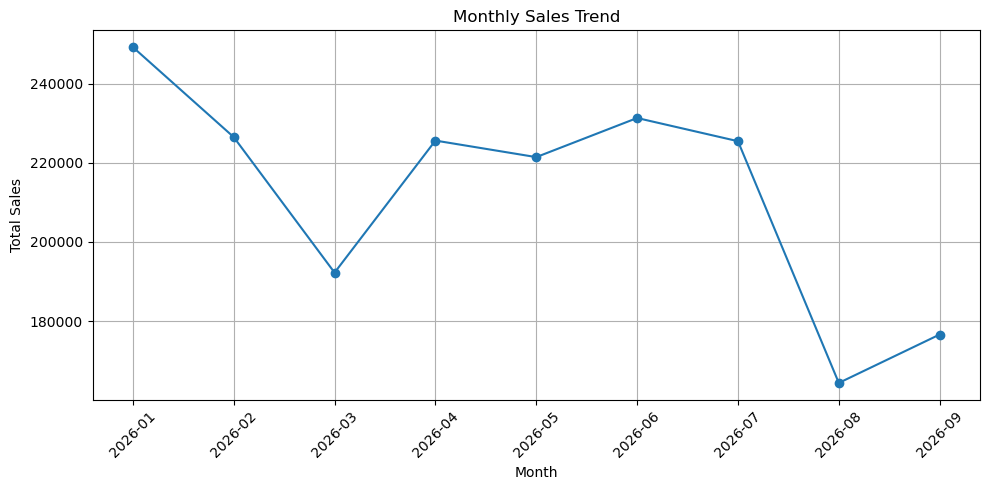

In [14]:
df["Month"] = df["Order Date"].dt.to_period("M")

monthly_sales = df.groupby("Month")["Total Amount"].sum()

monthly_sales.index = monthly_sales.index.astype(str)

plt.figure(figsize=(10, 5))
plt.plot(monthly_sales.index, monthly_sales.values, marker="o")

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

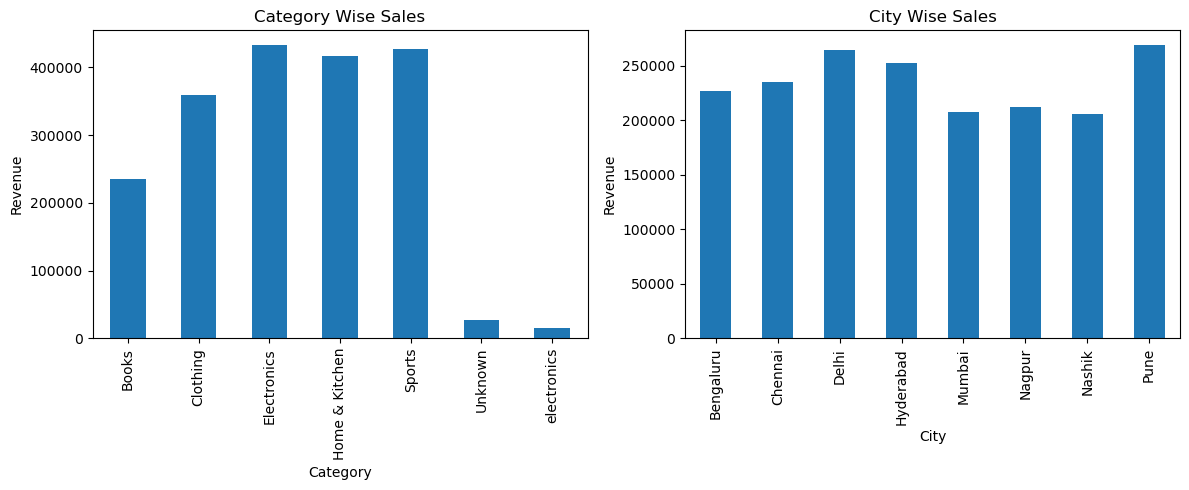

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

category_sales = df.groupby("Category")["Total Amount"].sum()
city_sales = df.groupby("City")["Total Amount"].sum()

category_sales.plot(kind="bar", ax=ax[0])
ax[0].set_title("Category Wise Sales")
ax[0].set_xlabel("Category")
ax[0].set_ylabel("Revenue")

city_sales.plot(kind="bar", ax=ax[1])
ax[1].set_title("City Wise Sales")
ax[1].set_xlabel("City")
ax[1].set_ylabel("Revenue")

plt.tight_layout()
plt.show()

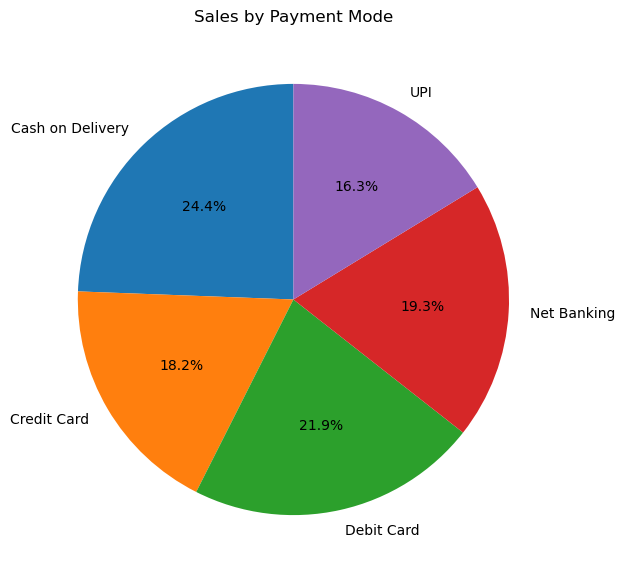

In [16]:
import pandas as pd
import matplotlib.pyplot as plt

# Load dataset
df = pd.read_csv("cleaned_ecommerce.csv")

# Calculate sales by payment mode
payment = df.groupby("Payment Mode")["Total Amount"].sum()

# Create pie chart
plt.figure(figsize=(7, 7))

plt.pie(payment,
        labels=payment.index,
        autopct="%1.1f%%",
        startangle=90)

plt.title("Sales by Payment Mode")

plt.show()

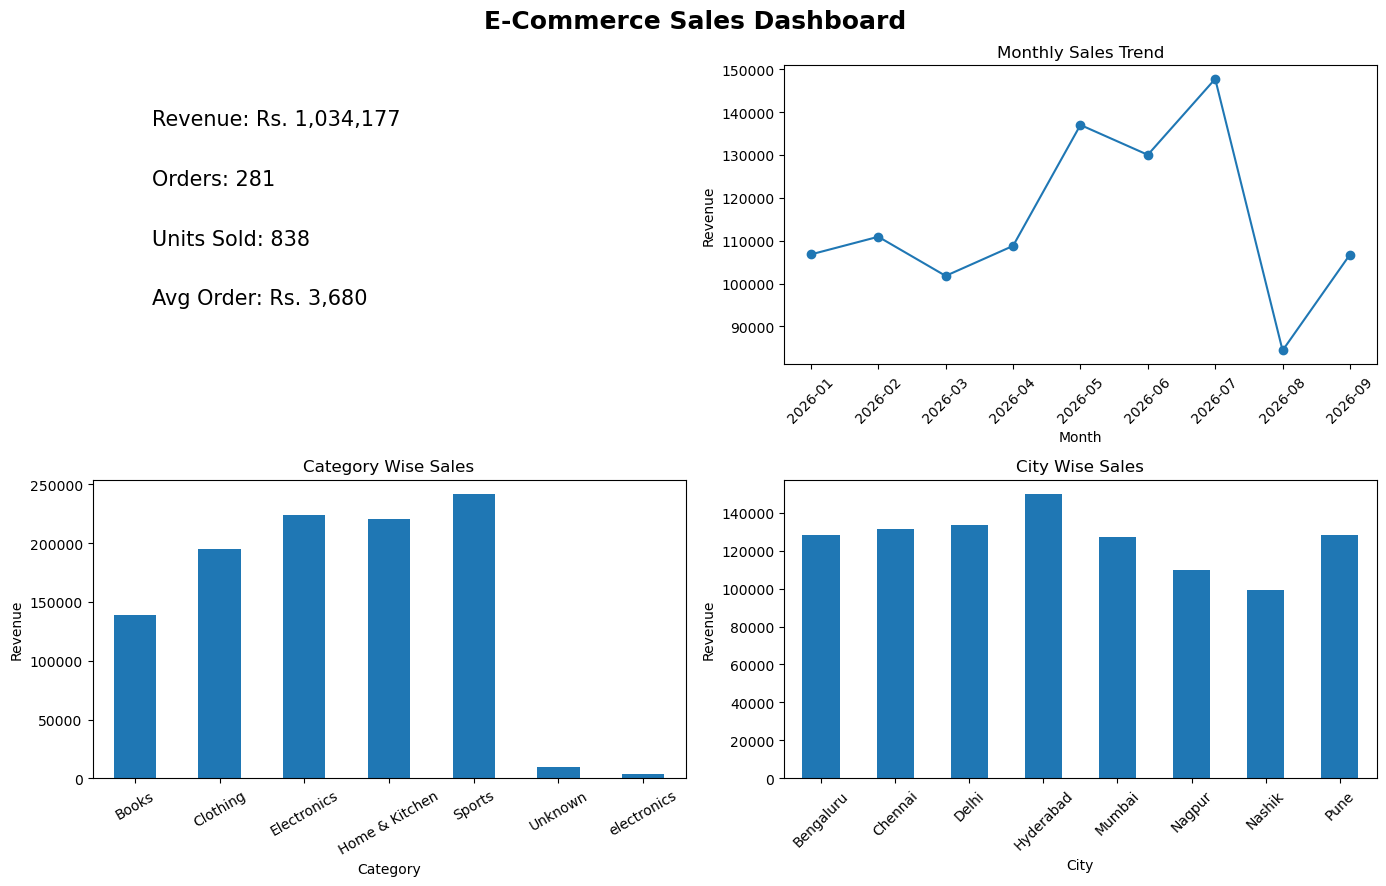

In [17]:
import pandas as pd
import matplotlib.pyplot as plt

# Load cleaned dataset
df = pd.read_csv("cleaned_ecommerce.csv")

# Convert date
df["Order Date"] = pd.to_datetime(df["Order Date"])

# Select completed sales
sales = df[df["Delivery Status"] == "Delivered"].copy()

# Calculate KPIs
revenue = sales["Total Amount"].sum()
orders = sales["Order ID"].nunique()
units = sales["Quantity"].sum()
avg_order = revenue / orders if orders > 0 else 0

# Monthly sales
sales["Month"] = sales["Order Date"].dt.to_period("M")
monthly = sales.groupby("Month")["Total Amount"].sum()
monthly.index = monthly.index.astype(str)

# Category and city sales
category = sales.groupby("Category")["Total Amount"].sum()
city = sales.groupby("City")["Total Amount"].sum()

# Create dashboard
fig, ax = plt.subplots(2, 2, figsize=(14, 9))

fig.suptitle("E-Commerce Sales Dashboard",
             fontsize=18, fontweight="bold")

# KPI cards
ax[0, 0].axis("off")
ax[0, 0].text(0.1, 0.8, f"Revenue: Rs. {revenue:,.0f}", fontsize=15)
ax[0, 0].text(0.1, 0.6, f"Orders: {orders}", fontsize=15)
ax[0, 0].text(0.1, 0.4, f"Units Sold: {units}", fontsize=15)
ax[0, 0].text(0.1, 0.2, f"Avg Order: Rs. {avg_order:,.0f}", fontsize=15)

# Line chart
ax[0, 1].plot(monthly.index, monthly.values, marker="o")
ax[0, 1].set_title("Monthly Sales Trend")
ax[0, 1].set_xlabel("Month")
ax[0, 1].set_ylabel("Revenue")
ax[0, 1].tick_params(axis="x", rotation=45)

# Category bar chart
category.plot(kind="bar", ax=ax[1, 0])
ax[1, 0].set_title("Category Wise Sales")
ax[1, 0].set_xlabel("Category")
ax[1, 0].set_ylabel("Revenue")
ax[1, 0].tick_params(axis="x", rotation=30)

# City bar chart
city.plot(kind="bar", ax=ax[1, 1])
ax[1, 1].set_title("City Wise Sales")
ax[1, 1].set_xlabel("City")
ax[1, 1].set_ylabel("Revenue")
ax[1, 1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.savefig("sales_dashboard.png", dpi=300)
plt.show()

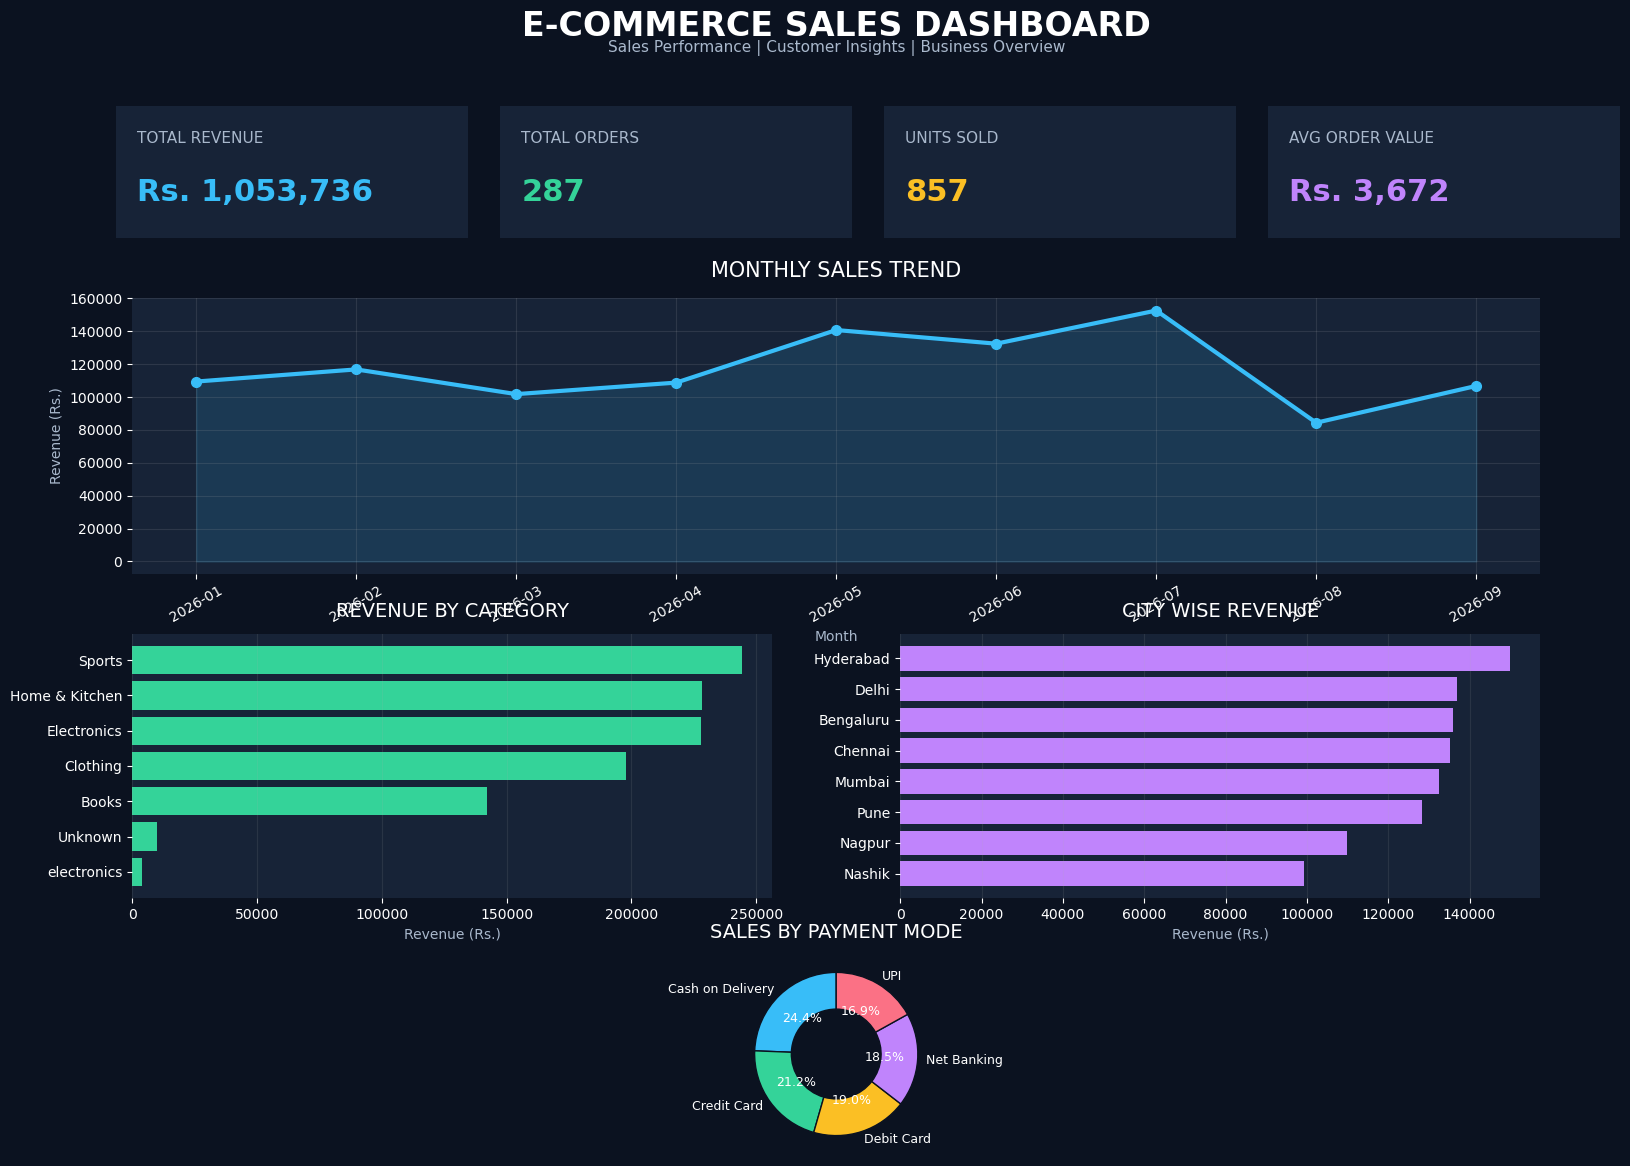

In [18]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# 1. Load cleaned data
df = pd.read_csv("cleaned_ecommerce.csv")

# Convert date
df["Order Date"] = pd.to_datetime(df["Order Date"])

# Select delivered orders
df["Delivery Status"] = df["Delivery Status"].str.strip().str.title()
sales = df[df["Delivery Status"] == "Delivered"].copy()

# 2. Calculate KPIs
revenue = sales["Total Amount"].sum()
orders = sales["Order ID"].nunique()
units = sales["Quantity"].sum()
avg_order = revenue / orders if orders > 0 else 0

# 3. Prepare chart data
sales["Month"] = sales["Order Date"].dt.to_period("M")

monthly = sales.groupby("Month")["Total Amount"].sum()
monthly.index = monthly.index.astype(str)

category = sales.groupby("Category")["Total Amount"].sum()
category = category.sort_values(ascending=True)

city = sales.groupby("City")["Total Amount"].sum()
city = city.sort_values(ascending=True)

payment = sales.groupby("Payment Mode")["Total Amount"].sum()

# 4. Dashboard colors
bg = "#0B1220"
panel = "#172337"
white = "#FFFFFF"
muted = "#A9B8CC"
blue = "#38BDF8"
green = "#34D399"
orange = "#FBBF24"
purple = "#C084FC"

plt.rcParams["font.family"] = "DejaVu Sans"

# 5. Create dashboard
fig = plt.figure(figsize=(16, 12), facecolor=bg)

fig.suptitle(
    "E-COMMERCE SALES DASHBOARD",
    fontsize=24,
    fontweight="bold",
    color=white,
    y=0.98
)

fig.text(
    0.5, 0.945,
    "Sales Performance | Customer Insights | Business Overview",
    ha="center",
    color=muted,
    fontsize=11
)

# 6. KPI Cards
kpis = [
    ("TOTAL REVENUE", f"Rs. {revenue:,.0f}", blue),
    ("TOTAL ORDERS", f"{orders:,}", green),
    ("UNITS SOLD", f"{units:,}", orange),
    ("AVG ORDER VALUE", f"Rs. {avg_order:,.0f}", purple)
]

for i, (name, value, color) in enumerate(kpis):

    ax = fig.add_axes([0.05 + i*0.24, 0.79, 0.22, 0.11])

    ax.set_facecolor(panel)
    ax.set_xticks([])
    ax.set_yticks([])

    for spine in ax.spines.values():
        spine.set_visible(False)

    ax.text(0.06, 0.72, name,
            color=muted, fontsize=11,
            transform=ax.transAxes)

    ax.text(0.06, 0.28, value,
            color=color, fontsize=22,
            fontweight="bold",
            transform=ax.transAxes)

# 7. Monthly Sales Line Chart
ax1 = fig.add_axes([0.06, 0.51, 0.88, 0.23])
ax1.set_facecolor(panel)

ax1.plot(
    monthly.index,
    monthly.values,
    color=blue,
    marker="o",
    linewidth=3,
    markersize=7
)

ax1.fill_between(
    range(len(monthly)),
    monthly.values,
    alpha=0.15,
    color=blue
)

ax1.set_title("MONTHLY SALES TREND",
              color=white, fontsize=15, pad=15)

ax1.set_xlabel("Month", color=muted)
ax1.set_ylabel("Revenue (Rs.)", color=muted)
ax1.tick_params(colors=white, axis="x", rotation=30)
ax1.tick_params(colors=white, axis="y")
ax1.grid(alpha=0.15)

for spine in ax1.spines.values():
    spine.set_visible(False)

# 8. Category Bar Chart
ax2 = fig.add_axes([0.06, 0.24, 0.40, 0.22])
ax2.set_facecolor(panel)

ax2.barh(category.index, category.values, color=green)

ax2.set_title("REVENUE BY CATEGORY",
              color=white, fontsize=14, pad=12)

ax2.set_xlabel("Revenue (Rs.)", color=muted)
ax2.tick_params(colors=white)
ax2.grid(axis="x", alpha=0.12)

for spine in ax2.spines.values():
    spine.set_visible(False)

# 9. City Bar Chart
ax3 = fig.add_axes([0.54, 0.24, 0.40, 0.22])
ax3.set_facecolor(panel)

ax3.barh(city.index, city.values, color=purple)

ax3.set_title("CITY WISE REVENUE",
              color=white, fontsize=14, pad=12)

ax3.set_xlabel("Revenue (Rs.)", color=muted)
ax3.tick_params(colors=white)
ax3.grid(axis="x", alpha=0.12)

for spine in ax3.spines.values():
    spine.set_visible(False)

# 10. Payment Mode Pie Chart
ax4 = fig.add_axes([0.30, 0.025, 0.40, 0.17])
ax4.set_facecolor(bg)

if payment.sum() > 0:
    ax4.pie(
        payment.values,
        labels=payment.index,
        autopct="%1.1f%%",
        startangle=90,
        colors=[blue, green, orange, purple, "#FB7185"],
        textprops={"color": white, "fontsize": 9},
        wedgeprops={"width": 0.45, "edgecolor": bg}
    )

ax4.set_title("SALES BY PAYMENT MODE",
              color=white, fontsize=14, pad=10)

# 11. Save dashboard
plt.savefig(
    "attractive_sales_dashboard.png",
    dpi=300,
    facecolor=fig.get_facecolor(),
    bbox_inches="tight"
)

plt.show()